# Reel Insights TMDB — Pandas Analysis

## Objective
Analyze the cleaned TMDB datasets using Pandas and answer the 10 required analysis questions.

In [1]:
import pandas as pd

movies = pd.read_csv("movies_cleaned.csv")
genres = pd.read_csv("genres_cleaned.csv")
movie_genres = pd.read_csv("movie_genres_cleaned.csv")
movie_keywords = pd.read_csv("movie_keywords_cleaned.csv")
cast = pd.read_csv("cast_cleaned.csv")
crew = pd.read_csv("crew_cleaned.csv")

print("All six cleaned datasets loaded successfully!")

for name, df in {
    "Movies": movies,
    "Genres": genres,
    "Movie Genres": movie_genres,
    "Movie Keywords": movie_keywords,
    "Cast": cast,
    "Crew": crew
}.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

All six cleaned datasets loaded successfully!
Movies: 2503 rows, 12 columns
Genres: 19 rows, 2 columns
Movie Genres: 6878 rows, 2 columns
Movie Keywords: 41681 rows, 3 columns
Cast: 24902 rows, 6 columns
Crew: 7289 rows, 6 columns


## Question 1: Total Unique Movies, Genres, Cast Members, and Crew Members

Calculate the total number of unique movies, genres, cast members, and crew members in the cleaned datasets.

In [2]:
summary = pd.DataFrame({
    "Metric": [
        "Unique Movies",
        "Unique Genres",
        "Unique Cast Members",
        "Unique Crew Members"
    ],
    "Count": [
        movies["movie_id"].nunique(),
        genres["genre_id"].nunique(),
        cast["person_id"].nunique(),
        crew["person_id"].nunique()
    ]
})

display(summary)

,Metric,Count
0,Unique Movies,2503
1,Unique Genres,19
2,Unique Cast Members,11300
3,Unique Crew Members,2848


### Insight
This analysis summarizes the unique movies, genres, cast members, and crew members represented in the cleaned datasets.

## Question 2: Missing or Zero Budget and Revenue

Identify movies with missing or zero budget/revenue and explain how these values are handled in the analysis.

In [3]:
budget_missing = movies["budget"].isna().sum()
budget_zero = movies["budget"].eq(0).sum()

revenue_missing = movies["revenue"].isna().sum()
revenue_zero = movies["revenue"].eq(0).sum()

missing_summary = pd.DataFrame({
    "Metric": [
        "Missing Budget",
        "Zero Budget",
        "Missing Revenue",
        "Zero Revenue"
    ],
    "Count": [
        budget_missing,
        budget_zero,
        revenue_missing,
        revenue_zero
    ]
})

display(missing_summary)

,Metric,Count
0,Missing Budget,0
1,Zero Budget,90
2,Missing Revenue,0
3,Zero Revenue,102


### Insight
Missing and zero budget or revenue values are treated as unavailable financial data and should be excluded from profit and ROI calculations. The counts above show how many records need this treatment.

## Question 3: Calculate Profit and Return on Investment (ROI)

Calculate profit and ROI for every movie with valid, non-zero budget and revenue.

In [ ]:
valid_financials = movies[
    movies["budget"].notna()
    & movies["revenue"].notna()
    & (movies["budget"] > 0)
    & (movies["revenue"] > 0)
].copy()

valid_financials["profit"] = (
    valid_financials["revenue"] - valid_financials["budget"]
)

valid_financials["ROI_percent"] = (
    valid_financials["profit"] / valid_financials["budget"]
) * 100

display(
    valid_financials[
        ["title", "budget", "revenue", "profit", "ROI_percent"]
    ].head(10)
)

print("Movies with valid budget and revenue:", len(valid_financials))

### Insight
Profit is calculated as revenue minus budget. ROI percentage measures profit relative to budget; positive ROI indicates revenue exceeded budget, while negative ROI indicates a loss.

## Question 4: Top 15 Movies by ROI

Identify the top 15 movies by ROI percentage, considering only movies with a budget of at least $1 million.

In [5]:
# Select movies with valid budget and revenue
valid_financials = movies[
    movies["budget"].notna()
    & movies["revenue"].notna()
    & (movies["budget"] >= 1_000_000)
    & (movies["budget"] > 0)
    & (movies["revenue"] > 0)
].copy()

# Calculate profit and ROI
valid_financials["profit"] = (
    valid_financials["revenue"] - valid_financials["budget"]
)

valid_financials["ROI_percent"] = (
    valid_financials["profit"] / valid_financials["budget"]
) * 100

# Display top 15 movies by ROI
top_roi = valid_financials.sort_values(
    "ROI_percent", ascending=False
).head(15)

display(
    top_roi[
        ["title", "budget", "revenue", "profit", "ROI_percent"]
    ]
)

,title,budget,revenue,profit,ROI_percent
1767,Dragon Ball Super: Broly,1000000.0,125002821.0,124002821.0,12400.282100
535,Snow White and the Seven Dwarfs,1488423.0,184925486.0,183437063.0,12324.256142
1791,The Rocky Horror Picture Show,1400000.0,171181400.0,169781400.0,12127.242857
467,Rocky,1000000.0,117253345.0,116253345.0,11625.334500
1227,Gone with the Wind,4000000.0,402352579.0,398352579.0,9958.814475
716,The Jungle Book,4000000.0,378000000.0,374000000.0,9350.000000
635,Cinderella,2900000.0,263600000.0,260700000.0,8989.655172
372,Saw,1200000.0,104045735.0,102845735.0,8570.477917
719,One Hundred and One Dalmatians,3600000.0,303000000.0,299400000.0,8316.666667
263,E.T. the Extra-Terrestrial,10500000.0,797307407.0,786807407.0,7493.403876


### Insight
The top 15 movies ranked by ROI percentage highlight films that generated the highest returns relative to their production budgets. Only movies with budgets of at least $1 million and valid, non-zero revenue are included.

## Question 5: Movies Released Per Year

Calculate the number of movies released each year and identify the year with the highest movie output.

In [6]:
movies["release_date"] = pd.to_datetime(
    movies["release_date"], errors="coerce"
)

movies["release_year"] = movies["release_date"].dt.year

yearly_movies = (
    movies.dropna(subset=["release_year"])
    .groupby("release_year")["movie_id"]
    .nunique()
    .reset_index(name="movie_count")
    .sort_values("release_year")
)

display(yearly_movies)

top_year = yearly_movies.loc[yearly_movies["movie_count"].idxmax()]

print(
    f"Year with the highest movie output: "
    f"{int(top_year['release_year'])} "
    f"({int(top_year['movie_count'])} movies)"
)

,release_year,movie_count
0,1921,1
1,1922,1
2,1927,1
3,1931,2
4,1936,1
...,...,...
84,2022,65
85,2023,62
86,2024,43
87,2025,26


Year with the highest movie output: 2016 (121 movies)


### Insight
The yearly movie counts reveal how movie production has changed over time. The year with the highest count represents the peak release year in this dataset.

## Question 6: Runtime Statistical Outliers

Identify movie runtime outliers using the Interquartile Range (IQR) method.

In [7]:
runtime = pd.to_numeric(movies["runtime"], errors="coerce")
valid_runtime = runtime.dropna()
valid_runtime = valid_runtime[valid_runtime > 0]

Q1 = valid_runtime.quantile(0.25)
Q3 = valid_runtime.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

runtime_outliers = movies.loc[
    runtime.index[
        (runtime < lower_bound) | (runtime > upper_bound)
    ]
].copy()

runtime_outliers["runtime"] = runtime.loc[runtime_outliers.index]

display(
    runtime_outliers[["title", "runtime"]]
    .sort_values("runtime", ascending=False)
)

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of runtime outliers:", len(runtime_outliers))

,title,runtime
324,Zack Snyder's Justice League,242
1227,Gone with the Wind,238
829,Once Upon a Time in America,229
1610,Lawrence of Arabia,228
1774,Ben-Hur,212
587,The Irishman,209
1277,Seven Samurai,207
1304,Killers of the Flower Moon,206
187,The Godfather Part II,202
20,The Lord of the Rings: The Return of the King,201


Lower bound: 58.5
Upper bound: 166.5
Number of runtime outliers: 60


### Insight
The IQR method identifies movies with unusually short or long runtimes compared with the central distribution. These outliers may represent unusually short films, extended productions, or possible data-quality issues.

## Question 7: Average Popularity by Primary Genre

Identify each movie's primary genre (the first genre listed) and calculate average popularity for each primary genre.

In [8]:

primary_genres = (
    movie_genres.drop_duplicates(subset="movie_id", keep="first")
    .merge(genres[["genre_id", "genre_name"]], on="genre_id", how="left")
)

popularity_by_genre = (
    primary_genres
    .merge(
        movies[["movie_id", "popularity"]],
        on="movie_id",
        how="inner"
    )
    .groupby("genre_name", dropna=False)["popularity"]
    .mean()
    .reset_index(name="average_popularity")
    .sort_values("average_popularity", ascending=False)
)

display(popularity_by_genre)

,genre_name,average_popularity
14,Science Fiction,21.261836
11,Music,18.324340
2,Animation,16.811212
7,Family,16.710635
0,Action,16.385188
16,War,15.470317
10,Horror,14.851835
1,Adventure,14.785510
8,Fantasy,13.022920
12,Mystery,12.427131


### Insight
Average popularity by primary genre helps compare audience interest across movie genres. The genre with the highest average popularity has the strongest average popularity score in this dataset.

## Question 8: Top 10 Prolific Actors and Average Movie Rating

Identify the top 10 actors by number of movies and calculate the average rating of their movies.

In [9]:
actor_movies = (
    cast[["person_id", "actor_name", "movie_id"]]
    .dropna(subset=["person_id", "movie_id"])
    .drop_duplicates(subset=["person_id", "movie_id"])
    .merge(
        movies[["movie_id", "vote_average"]],
        on="movie_id",
        how="left"
    )
)

top_actors = (
    actor_movies
    .groupby(["person_id", "actor_name"], dropna=False)
    .agg(
        movie_count=("movie_id", "nunique"),
        average_rating=("vote_average", "mean")
    )
    .reset_index()
    .sort_values("movie_count", ascending=False)
    .head(10)
)

display(top_actors)

,person_id,actor_name,movie_count,average_rating
679,2231,Samuel L. Jackson,39,6.938692
106,287,Brad Pitt,38,7.257289
127,380,Robert De Niro,38,7.228316
37,85,Johnny Depp,37,6.856973
13,31,Tom Hanks,33,7.289758
1272,5293,Willem Dafoe,32,7.114781
413,1245,Scarlett Johansson,32,7.056344
2674,13240,Mark Wahlberg,32,6.630063
161,500,Tom Cruise,31,7.040613
64,192,Morgan Freeman,31,6.963742


### Insight
The analysis identifies the 10 most prolific actors and compares the average ratings of movies they appeared in. A higher movie count indicates more appearances in the dataset, while average rating summarizes the ratings of those movies.


## Question 9: Duplicate Movie Titles with Release Years

Identify movie titles that appear more than once and display their release years.

In [10]:
duplicate_titles = movies[
    movies["title"].notna()
    & movies["title"].duplicated(keep=False)
].copy()

duplicate_titles["release_date"] = pd.to_datetime(
    duplicate_titles["release_date"], errors="coerce"
)

duplicate_titles["release_year"] = (
    duplicate_titles["release_date"].dt.year
)

duplicate_titles = duplicate_titles.sort_values(
    ["title", "release_year"]
)

display(
    duplicate_titles[
        ["title", "release_year", "movie_id"]
    ]
)

,title,release_year,movie_id
878,A Nightmare on Elm Street,1984,377
1928,A Nightmare on Elm Street,2010,23437
261,Aladdin,1992,812
339,Aladdin,2019,420817
792,Alice in Wonderland,1951,12092
...,...,...,...
1737,The Thing,2011,60935
744,Total Recall,1990,861
860,Total Recall,2012,64635
2500,Transformers,1987,1368168


### Insight
Duplicate movie titles may represent remakes, re-releases, or different movies sharing the same name. Comparing release years and movie IDs helps distinguish these records.

## Question 10: Popularity and Vote Count Relationship

Analyze the relationship between movie popularity and vote count, and identify unusual patterns or outliers.

,popularity,vote_count
popularity,1.00000,0.36085
vote_count,0.36085,1.00000


,title,popularity,vote_count
46,Spider-Man: No Way Home,438.4757,22429
2388,Disclosure Day,394.3346,2328
1315,Obsession,364.8722,4203
2248,Backrooms,258.4743,2483
62,Spider-Man,180.5936,20991
35,Spider-Man: Homecoming,169.0857,23456
713,Project Hail Mary,162.7023,6750
1465,Michael,108.7248,3846
114,Spider-Man: Far From Home,105.6644,17240
2452,Mortal Kombat II,99.5231,2260


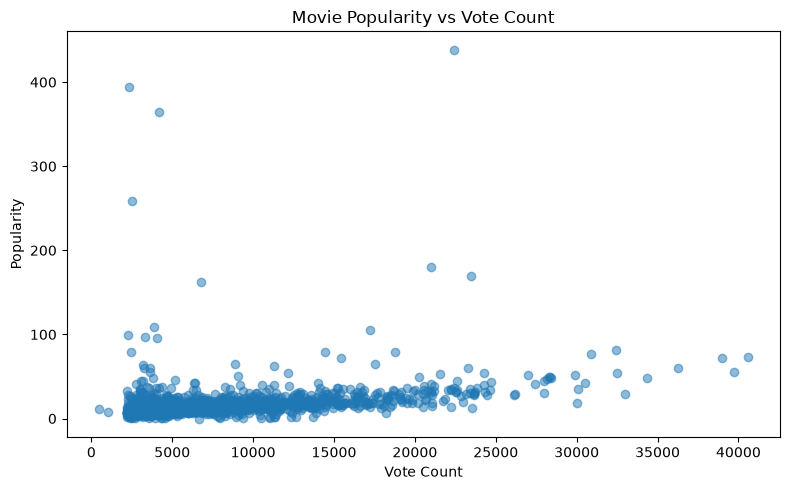

In [11]:
import matplotlib.pyplot as plt

popularity_votes = movies[
    ["title", "popularity", "vote_count"]
].copy()

popularity_votes["popularity"] = pd.to_numeric(
    popularity_votes["popularity"], errors="coerce"
)
popularity_votes["vote_count"] = pd.to_numeric(
    popularity_votes["vote_count"], errors="coerce"
)

popularity_votes = popularity_votes.dropna(
    subset=["popularity", "vote_count"]
)

display(
    popularity_votes[
        ["popularity", "vote_count"]
    ].corr()
)

# Identify movies with unusually high popularity using IQR
q1 = popularity_votes["popularity"].quantile(0.25)
q3 = popularity_votes["popularity"].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

popularity_outliers = popularity_votes[
    popularity_votes["popularity"] > upper_limit
].sort_values("popularity", ascending=False)

display(popularity_outliers.head(10))

plt.figure(figsize=(8, 5))
plt.scatter(
    popularity_votes["vote_count"],
    popularity_votes["popularity"],
    alpha=0.5
)
plt.xlabel("Vote Count")
plt.ylabel("Popularity")
plt.title("Movie Popularity vs Vote Count")
plt.tight_layout()
plt.show()

### Insight
The correlation result indicates the direction and strength of the relationship between popularity and vote count. Movies with unusually high popularity are identified using the IQR method; these outliers may warrant further investigation.